In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
from QGP.Soliton_Gen import *
from Utilities import *
from Eigenvalues import *
import config

# Eigenvalues

## Stable

### $c = c^* + \varepsilon$

In [3]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_st_eps = c_star + eps

In [4]:
k = -50
L = 200
N = 400_001
w_st_test, x_st_test = soliton(c_st_eps, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [5]:
w_st_eps = w_st_test
x_st_eps = x_st_test

In [6]:
#x = np.linspace(-L, L, N)

h = x_st_test[1] - x_st_test[0] #x[1] - x[0]  # 
us = w_st_test #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_st_eps)

# pocos autovalores
evals, evecs = spla.eigs(M, k=64, sigma=0, which='LM')#, which='LM') #, which='LR')
print("Eigenvalues:")
print(evals)

Eigenvalues:
[-9.29530066e-11-4.80594081e-05j -9.29530066e-11+4.80594081e-05j
 -2.81725022e-03+0.00000000e+00j  2.82435153e-03+0.00000000e+00j
 -4.15229925e-05-8.65361313e-03j -4.15229925e-05+8.65361313e-03j
 -5.12961383e-05-1.99772002e-02j -5.12961383e-05+1.99772002e-02j
  8.54788853e-06-2.72278535e-02j  8.54788853e-06+2.72278535e-02j
  8.57478702e-05-4.11870966e-02j  8.57478702e-05+4.11870966e-02j
 -1.30144194e-04-4.84505188e-02j -1.30144194e-04+4.84505188e-02j
  1.63661847e-05-6.50314775e-02j  1.63661847e-05+6.50314775e-02j
 -6.39788755e-05-7.33302183e-02j -6.39788755e-05+7.33302183e-02j
 -1.26345663e-04-9.18889302e-02j -1.26345663e-04+9.18889302e-02j
  8.59059822e-05-1.01917401e-01j  8.59059822e-05+1.01917401e-01j
 -1.51289560e-05-1.22260404e-01j -1.51289560e-05+1.22260404e-01j
  5.08803695e-05-1.33759186e-01j  5.08803695e-05+1.33759186e-01j
  1.62313251e-05-1.56003588e-01j  1.62313251e-05+1.56003588e-01j
  1.28638768e-04-1.69508175e-01j  1.28638768e-04+1.69508175e-01j
 -5.64315078

In [7]:
# Tolerance for selecting nearly real eigenvalues
#imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
#real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

#if real_like_idx.size == 0:
    #raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = np.argmax(np.real(evals)) #real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (0.002824351531045192+0j)


In [8]:
evals_eps = evals
evecs_eps = evecs

### $c = c^* + 2\cdot\varepsilon$

In [9]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_st_two_eps = c_star + 2 * eps

In [10]:
k = -50
L = 200
N = 400_001
w_st_test, x_st_test = soliton(c_st_two_eps, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [11]:
w_st_two_eps = w_st_test
x_st_two_eps = x_st_test

In [12]:
k = -50
L = 200
N = 400_001

#x = np.linspace(-L, L, N)

h = x_st_two_eps[1] - x_st_two_eps[0] #x[1] - x[0]  # 
us = w_st_two_eps #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_st_two_eps)

# pocos autovalores
evals, evecs = spla.eigs(M, k=64, sigma=0, which='LM')#, which='LM') #, which='LR')
print("Eigenvalues:")
print(evals)

Eigenvalues:
[-1.07085266e-11-4.65786034e-05j -1.07085266e-11+4.65786034e-05j
  1.67828391e-03+0.00000000e+00j -1.67858225e-03+0.00000000e+00j
 -7.04389273e-05-8.44514273e-03j -7.04389273e-05+8.44514273e-03j
 -1.77998362e-04-1.87993139e-02j -1.77998362e-04+1.87993139e-02j
  3.31289351e-05-2.68797993e-02j  3.31289351e-05+2.68797993e-02j
 -3.29134482e-05-3.88535491e-02j -3.29134482e-05+3.88535491e-02j
 -2.72499830e-04-4.73921381e-02j -2.72499830e-04+4.73921381e-02j
  1.68963692e-04-6.21384822e-02j  1.68963692e-04+6.21384822e-02j
  6.95026642e-05-7.15848448e-02j  6.95026642e-05+7.15848448e-02j
 -1.11634282e-04-8.83927089e-02j -1.11634282e-04+8.83927089e-02j
  3.34596993e-05-1.00382509e-01j  3.34596993e-05+1.00382509e-01j
  8.24902322e-05-1.18921365e-01j  8.24902322e-05+1.18921365e-01j
 -1.20575077e-04-1.32271045e-01j -1.20575077e-04+1.32271045e-01j
 -1.80305435e-05-1.53072092e-01j -1.80305435e-05+1.53072092e-01j
  3.67793613e-04-1.68111315e-01j  3.67793613e-04+1.68111315e-01j
 -2.51629954

In [13]:
# Tolerance for selecting nearly real eigenvalues
#imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
#real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

#if real_like_idx.size == 0:
#    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = np.argmax(np.real(evals))

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (0.0016782839140005092+0j)


In [14]:
evals_two_eps = evals
evecs_two_eps = evecs

### $c = c^* + 3\varepsilon$

In [15]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_st_three_eps = c_star + 3 * eps

In [16]:
k = -50
L = 200
N = 400_001
w_st_test, x_st_test = soliton(c_st_three_eps, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [17]:
w_st_three_eps = w_st_test
x_st_three_eps = x_st_test

In [18]:
k = -50
L = 200
N = 400_001

#x = np.linspace(-L, L, N)

h = x_st_three_eps[1] - x_st_three_eps[0] #x[1] - x[0]  # 
us = w_st_three_eps #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_st_three_eps)

# pocos autovalores
evals, evecs = spla.eigs(M, k=64, sigma=0, which="LM")#, which='LM') #, which='LR')
print("Eigenvalues:")
print(evals)

Eigenvalues:
[-1.02935687e-09-4.32637314e-05j -1.02935687e-09+4.32637314e-05j
  1.03882819e-03+0.00000000e+00j -1.11991929e-03+0.00000000e+00j
  7.04318318e-05-8.05233944e-03j  7.04318318e-05+8.05233944e-03j
  7.10138522e-06-1.66906427e-02j  7.10138522e-06+1.66906427e-02j
  6.89223928e-05-2.53062037e-02j  6.89223928e-05+2.53062037e-02j
 -4.24445845e-05-3.63933986e-02j -4.24445845e-05+3.63933986e-02j
  6.55788009e-04-4.60736079e-02j  6.55788009e-04+4.60736079e-02j
  4.29482389e-05-5.78934303e-02j  4.29482389e-05+5.78934303e-02j
 -4.98067178e-04-6.97068602e-02j -4.98067178e-04+6.97068602e-02j
  3.04279637e-04-8.49679311e-02j  3.04279637e-04+8.49679311e-02j
 -6.53114448e-04-9.69451010e-02j -6.53114448e-04+9.69451010e-02j
 -3.81444150e-05-1.15434566e-01j -3.81444150e-05+1.15434566e-01j
  1.20224365e-04-1.29032792e-01j  1.20224365e-04+1.29032792e-01j
 -5.45605334e-04-1.48876080e-01j -5.45605334e-04+1.48876080e-01j
 -5.76819437e-05-1.65955852e-01j -5.76819437e-05+1.65955852e-01j
  8.83315690

In [19]:
# Tolerance for selecting nearly real eigenvalues
#imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
#real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

#if real_like_idx.size == 0:
#    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = np.argmax(np.real(evals))

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (0.0010388281873134056+0j)


In [20]:
evals_three_eps = evals
evecs_three_eps = evecs

In [21]:
evals_eps_ = np.sort_complex(evals_eps)
evals_two_eps_ = np.sort_complex(evals_two_eps)
evals_three_eps_ = np.sort_complex(evals_three_eps)

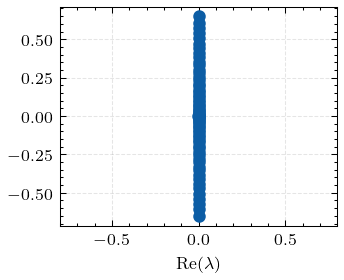

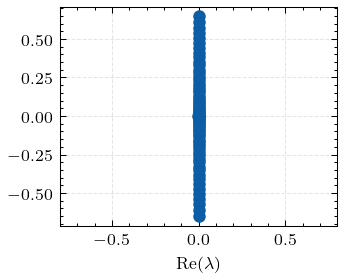

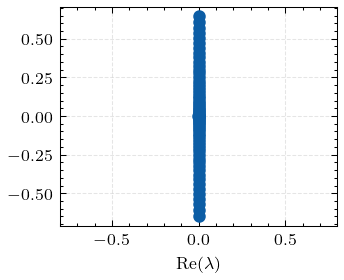

In [85]:
# Fixed canvas for all figures (no tight bounding-box cropping)
left, right, bottom, top = 0.24, 0.98, 0.22, 0.95

# c = c* + eps
fig1, ax1 = plt.subplots(figsize=(2.5, 2))
ax1.plot(
    np.real(evals_eps_), np.imag(evals_eps_),
    marker="o", ms=5, ls="", color="C0"
 )
#ax1.set_title(r"$c = c^* + \\varepsilon$")
ax1.set_xlabel(r"$\mathrm{Re}(\lambda)$")
#ax1.set_ylabel(r"$\mathrm{Im}(\lambda)$", rotation="horizontal")
ax1.set_xlim(-0.8, 0.8)
fig1.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig1.savefig("Eigs_imgs/eigs_stables_eps.pdf", dpi=300)
plt.show()

# c = c* + 2 eps
fig2, ax2 = plt.subplots(figsize=(2.5, 2))
ax2.plot(
    np.real(evals_two_eps_), np.imag(evals_two_eps_),
    marker="o", ms=5, ls="", color="C0"
 )
#ax2.set_title(r"$c = c^* + 2\\varepsilon$")
ax2.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax2.set_ylabel("")
ax2.set_xlim(-0.8, 0.8)
fig2.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig2.savefig("Eigs_imgs/eigs_stables_two_eps.pdf", dpi=300)
plt.show()

# c = c* + 3 eps
fig3, ax3 = plt.subplots(figsize=(2.5, 2))
ax3.plot(
    np.real(evals_three_eps_), np.imag(evals_three_eps_),
    marker="o", ms=5, ls="", color="C0"
 )
#ax3.set_title(r"$c = c^* + 3\\varepsilon$")
ax3.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax3.set_ylabel("")
ax3.set_xlim(-0.8, 0.8)
fig3.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig3.savefig("Eigs_imgs/eigs_stables_three_eps.pdf", dpi=300)
plt.show()

## Unstable

### $c = c^* - \varepsilon$

In [2]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns_eps = c_star - eps

In [3]:
k = -50
L = 200
N = 400_001
w_uns_test, x_uns_test = soliton(c_uns_eps, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [4]:
w_uns_eps = w_uns_test
x_uns_eps = x_uns_test

In [5]:
k = -50

#x = np.linspace(-L, L, N)

h = x_uns_eps[1] - x_uns_eps[0] #x[1] - x[0]  # 
us = w_uns_eps #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_uns_eps)

# pocos autovalores
evals, evecs = spla.eigs(M,  k=128, sigma=0.1, which='LM')#, which='LM') #, which='LR') #128
print("Eigenvalues:")
print(evals)

Eigenvalues:
[ 1.05547803e-01+0.00000000e+00j  5.90284746e-09-2.17524032e-02j
  5.90284746e-09+2.17524032e-02j  6.26223894e-09-1.23083166e-02j
  6.26223894e-09+1.23083166e-02j -2.94725758e-10-3.27339736e-03j
 -2.94725758e-10+3.27339736e-03j  5.69737724e-09-2.95194850e-05j
  5.69737724e-09+2.95194850e-05j  6.18777628e-09-3.70004022e-02j
  6.18777628e-09+3.70004022e-02j  5.23755961e-09-4.45869873e-02j
  5.23755961e-09+4.45869873e-02j  5.50825068e-09-6.37712152e-02j
  5.50825068e-09+6.37712152e-02j  5.67982632e-09-6.93588826e-02j
  5.67982632e-09+6.93588826e-02j  6.19598196e-09-9.33037830e-02j
  6.19598196e-09+9.33037830e-02j  5.13136721e-09-9.66736239e-02j
  5.13136721e-09+9.66736239e-02j  2.51729682e-04-1.26523421e-01j
  2.51729682e-04+1.26523421e-01j -2.51718581e-04-1.26523416e-01j
 -2.51718581e-04+1.26523416e-01j  6.55759943e-04-1.61512533e-01j
  6.55759943e-04+1.61512533e-01j -6.55748779e-04-1.61512534e-01j
 -6.55748779e-04+1.61512534e-01j -1.05547792e-01+0.00000000e+00j
  5.55881753

In [6]:
# Tolerance for selecting nearly real eigenvalues
imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

if real_like_idx.size == 0:
    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (0.10554780290986361+0j)


In [7]:
evals_uns_eps = evals
evecs_uns_eps = evecs

### $c = c^* - 2\varepsilon$

In [8]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns_two_eps = c_star - 2 * eps

In [9]:
k = -50
L = 200
N = 400_001
w_uns_test, x_uns_test = soliton(c_uns_two_eps, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [10]:
w_uns_two_eps = w_uns_test
x_uns_two_eps = x_uns_test

In [11]:
k = -50
L = 200
N = 400_001

#x = np.linspace(-L, L, N)

h = x_uns_two_eps[1] - x_uns_two_eps[0] #x[1] - x[0]  # 
us = w_uns_two_eps #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_uns_two_eps)

# pocos autovalores
evals, evecs = spla.eigs(M, k=128, sigma=0.4, which='LM')#, which='LM') #, which='LR') 128
print("Eigenvalues:")
print(evals)

Eigenvalues:
[ 4.36038664e-01+0.00000000e+00j -6.84554080e-11-4.57664619e-02j
 -6.84554080e-11+4.57664619e-02j -2.48431553e-10-3.55808382e-02j
 -2.48431553e-10+3.55808382e-02j -6.87780388e-11-2.24104133e-02j
 -6.87780388e-11+2.24104133e-02j -8.78002115e-11-1.17385613e-02j
 -8.78002115e-11+1.17385613e-02j  6.61458777e-10-2.21334277e-03j
  6.61458777e-10+2.21334277e-03j  2.93884941e-05+0.00000000e+00j
 -2.93890960e-05+0.00000000e+00j -2.92508684e-10-6.11053874e-02j
 -2.92508684e-10+6.11053874e-02j -2.28122743e-10-7.08863504e-02j
 -2.28122743e-10+7.08863504e-02j -2.88474300e-10-8.91092562e-02j
 -2.88474300e-10+8.91092562e-02j -1.40510936e-10-9.84251927e-02j
 -1.40510936e-10+9.84251927e-02j -2.68265243e-10-1.20216174e-01j
 -2.68265243e-10+1.20216174e-01j -1.97971028e-10-1.28893396e-01j
 -1.97971028e-10+1.28893396e-01j -2.55243771e-10-1.54902185e-01j
 -2.55243771e-10+1.54902185e-01j -2.39455566e-10-1.62691707e-01j
 -2.39455566e-10+1.62691707e-01j -2.43798259e-10-1.93533363e-01j
 -2.43798259

In [12]:
# Tolerance for selecting nearly real eigenvalues
imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

if real_like_idx.size == 0:
    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (0.43603866421089493+0j)


In [13]:
evals_uns_two_eps = evals
evecs_uns_two_eps = evecs

### $c = c^* - 3\varepsilon$

In [14]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns_three_eps = c_star - 3 * eps

In [15]:
k = -50
L = 200
N = 400_001
w_uns_test, x_uns_test, eta, theta = soliton(c_uns_three_eps, k, soliton_type="dark", L=L, N=N, get_profs=True)

Creating soliton...
Soliton created


In [16]:
w_uns_three_eps = w_uns_test
x_uns_three_eps = x_uns_test

In [17]:
k = -50
L = 200
N = 400_001

#x = np.linspace(-L, L, N)

h = x_uns_three_eps[1] - x_uns_three_eps[0] #x[1] - x[0]  # 
us = w_uns_three_eps #theo_uns(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_uns_three_eps)#, profs=(eta, theta))

# pocos autovalores
evals, evecs = spla.eigs(M, k=128, sigma=1.2, which='LM')#k=4, sigma=1.5)#, which='SI') #, which='LR') # sigma=0 k=128
print("Eigenvalues:")
print(evals)

Eigenvalues:
[ 1.51942147e+00+0.00000000e+00j -2.80290613e-09-3.37942971e-01j
 -2.80290613e-09+3.37942971e-01j -2.89187740e-09-3.26856690e-01j
 -2.89187740e-09+3.26856690e-01j -2.78566681e-09-2.88236844e-01j
 -2.78566681e-09+2.88236844e-01j -2.91156077e-09-2.76759316e-01j
 -2.91156077e-09+2.76759316e-01j -2.84698398e-09-2.42782166e-01j
 -2.84698398e-09+2.42782166e-01j -2.92041036e-09-2.31082243e-01j
 -2.92041036e-09+2.31082243e-01j -2.82472579e-09-2.01426013e-01j
 -2.82472579e-09+2.01426013e-01j -2.90793878e-09-1.89654339e-01j
 -2.90793878e-09+1.89654339e-01j -2.85582447e-09-1.63967289e-01j
 -2.85582447e-09+1.63967289e-01j -2.92038327e-09-1.52249954e-01j
 -2.92038327e-09+1.52249954e-01j -2.85264856e-09-1.30143080e-01j
 -2.85264856e-09+1.30143080e-01j -2.91790303e-09-1.18573352e-01j
 -2.91790303e-09+1.18573352e-01j -2.85047452e-09-9.96129296e-02j
 -2.85047452e-09+9.96129296e-02j -2.87980573e-09-8.82405095e-02j
 -2.87980573e-09+8.82405095e-02j -2.89110891e-09-7.19416158e-02j
 -2.89110891

In [18]:
# Tolerance for selecting nearly real eigenvalues
imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

if real_like_idx.size == 0:
    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (1.519421474496196+0j)


In [19]:
evals_uns_three_eps = evals
evecs_uns_three_eps = evecs

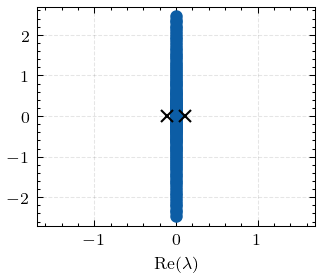

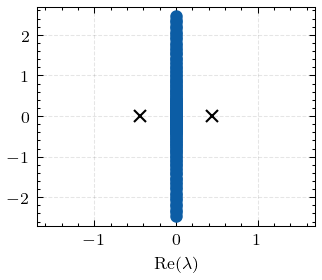

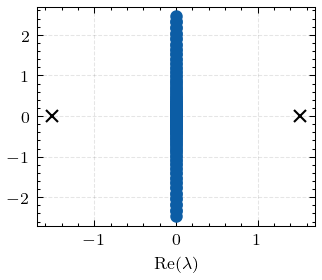

In [43]:
# Fixed canvas for all figures (no tight bounding-box cropping)
left, right, bottom, top = 0.24, 0.98, 0.22, 0.95
real_tol = 1e-4
imag_tol = 1e-5

def classify_eigs(evals, real_tol=1e-10, imag_tol=1e-10):
    real_part = np.real(evals)
    imag_part = np.imag(evals)
    is_zero = (np.abs(real_part) <= real_tol) & (np.abs(imag_part) <= imag_tol)
    is_pure_real_nonzero = (np.abs(imag_part) <= imag_tol) & (np.abs(real_part) > real_tol)
    is_other = ~(is_zero | is_pure_real_nonzero)
    return is_zero, is_pure_real_nonzero, is_other

# c = c* + eps
fig1, ax1 = plt.subplots(figsize=(2.5, 2))
_, mask_real_1, mask_other_1 = classify_eigs(evals_uns_eps, real_tol=real_tol, imag_tol=imag_tol)
ax1.plot(
    np.real(evals_uns_eps[mask_other_1]), np.imag(evals_uns_eps[mask_other_1]),
    marker="o", ms=5, ls="", color="C0"
 )
ax1.plot(
    np.real(evals_uns_eps[mask_real_1]), np.imag(evals_uns_eps[mask_real_1]),
    marker="x", ms=6, ls="", color="k"
 )
#ax1.set_title(r"$c = c^* + \\varepsilon$")
ax1.set_xlabel(r"$\mathrm{Re}(\lambda)$")
#ax1.set_ylabel(r"$\mathrm{Im}(\lambda)$", rotation="horizontal")
ax1.set_xlim(-1.7, 1.7)
fig1.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig1.savefig("Eigs_imgs/eigs_unstables_eps.pdf", dpi=300)
plt.show()

# c = c* + 2 eps
fig2, ax2 = plt.subplots(figsize=(2.5, 2))
_, mask_real_2, mask_other_2 = classify_eigs(evals_uns_two_eps, real_tol=real_tol, imag_tol=imag_tol)
ax2.plot(
    np.real(evals_uns_two_eps[mask_other_2]), np.imag(evals_uns_two_eps[mask_other_2]),
    marker="o", ms=5, ls="", color="C0"
 )
ax2.plot(
    np.real(evals_uns_two_eps[mask_real_2]), np.imag(evals_uns_two_eps[mask_real_2]),
    marker="x", ms=6, ls="", color="k"
 )
#ax2.set_title(r"$c = c^* + 2\\varepsilon$")
ax2.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax2.set_ylabel("")
ax2.set_xlim(-1.7, 1.7)
fig2.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig2.savefig("Eigs_imgs/eigs_unstables_two_eps.pdf", dpi=300)
plt.show()

# c = c* + 3 eps
fig3, ax3 = plt.subplots(figsize=(2.5, 2))
_, mask_real_3, mask_other_3 = classify_eigs(evals_uns_three_eps, real_tol=real_tol, imag_tol=imag_tol)
ax3.plot(
    np.real(evals_uns_three_eps[mask_other_3]), np.imag(evals_uns_three_eps[mask_other_3]),
    marker="o", ms=5, ls="", color="C0"
 )
ax3.plot(
    np.real(evals_uns_three_eps[mask_real_3]), np.imag(evals_uns_three_eps[mask_real_3]),
    marker="x", ms=6, ls="", color="k"
 )
#ax3.set_title(r"$c = c^* + 3\\varepsilon$")
ax3.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax3.set_ylabel("")
ax3.set_xlim(-1.7, 1.7)
fig3.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
fig3.savefig("Eigs_imgs/eigs_unstables_three_eps.pdf", dpi=300)
plt.show()

### Simulation

In [2]:
def get_eta(N, evals, evecs):
    # Tolerance for selecting nearly real eigenvalues
    imag_tol = 1e-8
    
    # Indices of eigenvalues with imaginary part close to zero
    real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]
    
    if real_like_idx.size == 0:
        raise RuntimeError("No eigenvalues found with imaginary part close to zero.")
    
    # Among the nearly real eigenvalues, pick the one with largest real part
    idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]
    
    lam = evals[idx]
    vec = evecs[:, idx]

    p = vec[:N]
    q = vec[N:]
    
    print("Largest non-complex eigenvalue =", lam)

    eta = p + 1j*q
    return eta

In [3]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns_three_eps = c_star - 3 * eps

In [4]:
k = -50
L_theo = 200
N_theo = 400_001
w_uns_three_eps, x_uns_three_eps = soliton(c_uns_three_eps, k, soliton_type="dark", L=L_theo, N=N_theo, as_func=True)

Creating soliton...
Soliton created


In [5]:
k = -50
L = 100
N = 200_001

x = np.linspace(-L, L, N)

h = x[1] - x[0]
us = w_uns_three_eps(x)

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_uns_three_eps)#, profs=(eta, theta))

# pocos autovalores
evals_uns_three_eps, evecs_uns_three_eps = spla.eigs(M, k=128, sigma=0)#, which='LM') #, which='LR')
#print("Eigenvalues:")
#print(evals)

In [6]:
eta_three_eps = get_eta(N, evals_uns_three_eps, evecs_uns_three_eps)

def init_cond_pert(x, w_uns, eta, eps=1e-2):
    output = w_uns(x) + eps * eta
    return output

init_cond_three_eps = lambda x: init_cond_pert(x, w_uns_three_eps, eta_three_eps)

Largest non-complex eigenvalue = (1.5194602909147221+0j)


In [11]:
# Set theo solution
def w_dark_theo(x, t):
    output = w_uns_three_eps(x - c_uns_three_eps * t)
    return output

In [7]:
Nt = 10_000 #10_000
tf = 1 #5 #1 #15

In [8]:
# perturbed
pars = {"k": k}
w_uns_pert_three_eps = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_uns_pert_three_eps.set_init_condition(init_cond_three_eps)
w_uns_pert_three_eps.solve(b_tol=1e-4, energy_perc=.1)

Iteration  1  of  10000 . Newton Error:  2.4714374117773225e-11 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  2.472573460322424e-11 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  2.4742513271595012e-11 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  2.4776107572523703e-11 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  2.4753833784302656e-11 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  2.474390929484522e-11 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  2.4748048758798537e-11 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  2.4769939858840042e-11 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  2.475996907325314e-11 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  2.4861230577666396e-11 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  2.4801384152557436e-11 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  2.47956638398

In [12]:
w_uns_pert_three_eps.w_theo = w_dark_theo

In [ ]:
error = []
t = w_uns_pert_three_eps.t
h = w_uns_pert_three_eps.h

for j in range(len(t)):
    w_num = w_uns_pert_three_eps.w[j, :]
    w_th = w_dark_theo(x, t[j])
    er = np.sqrt(h) * np_norm((w_num - w_th), 2)
    error.append(er)

error = np.array(error)

In [21]:
from scipy.optimize import curve_fit
def line_func(t, C, l):
    return l*t + C

t_cond = t <= 1
pars, other = curve_fit(line_func,  t[t_cond],  np.log(error[t_cond]))
C, l_ = pars

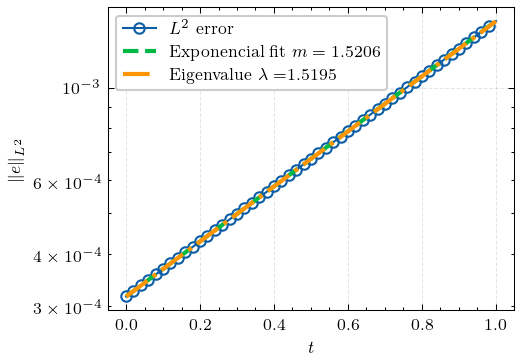

In [59]:
lam = 1.5194602909147221
plt.plot(t, error, label=r"$L^2$ error", ms=5, marker="o", markerfacecolor="none", markevery=200)
plt.plot(t, np.exp(line_func(t, C, l_)), marker="none",
         label="Exponencial fit $m={}$".format(round(l_, 4)), lw=2)
plt.plot(t, np.exp(line_func(t, C, np.real(lam))), marker="none",
         label=r"Eigenvalue $\lambda=${}".format(round(np.real(lam), 4)), lw=2)
plt.plot()
plt.plot()
plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\|e\|_{L^2}$")
plt.legend()

plt.savefig("Eigs_imgs/error_uns_pert_three_eps.pdf", dpi=300, bbox_inches='tight')
plt.show()

## Black soliton test

In [2]:
k = -50
L = 100
N = 200_001
c_zero = 0
w_uns_black, x_uns_black = soliton(c_zero, k, soliton_type="dark", L=L, N=N)

Creating soliton...
Soliton created


In [3]:
L = 100
N = 200_001

h = x_uns_black[1] - x_uns_black[0]
us = w_uns_black

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(us, D1, D2, k, c_zero)

# Eigenvalues
evals, evecs = spla.eigs(M, k=128, sigma=1)#, which='LM') #, which='LR')
print("Eigenvalues:")
print(evals)

idx = np.argmax(np.real(evals))
lam = evals[idx]
vec = evecs[:, idx]

Eigenvalues:
[ 4.47752946e-13-3.44662539e-01j  4.47752946e-13+3.44662539e-01j
  7.59392549e-14-3.12688432e-01j  7.59392549e-14+3.12688432e-01j
  1.44706469e-12-2.49053499e-01j  1.44706469e-12+2.49053499e-01j
  1.25000010e-12-2.19167469e-01j  1.25000010e-12+2.19167469e-01j
  9.78883641e-13-1.69319420e-01j  9.78883641e-13+1.69319420e-01j
 -6.30162589e-13-1.41762548e-01j -6.30162589e-13+1.41762548e-01j
  9.25703958e-13-1.03639764e-01j  9.25703958e-13+1.03639764e-01j
  2.45681253e-12-7.82738960e-02j  2.45681253e-12+7.82738960e-02j
  3.93352018e-13-4.88428448e-02j  3.93352018e-13+4.88428448e-02j
  2.18558505e-12-2.48064302e-02j  2.18558505e-12+2.48064302e-02j
 -1.05463237e-03+0.00000000e+00j  1.05463236e-03+0.00000000e+00j
  3.53050922e-13-3.44942288e-04j  3.53050922e-13+3.44942288e-04j
 -2.73847611e-12-4.23529463e-01j -2.73847611e-12+4.23529463e-01j
  9.61231095e-13-4.57170556e-01j  9.61231095e-13+4.57170556e-01j
 -5.25801624e-13-5.52362911e-01j -5.25801624e-13+5.52362911e-01j
  1.28863586

In [4]:
evals_zero = evals
evec_zero = evecs

In [5]:
# Tolerance for selecting nearly real eigenvalues
imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

if real_like_idx.size == 0:
    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

N = us.size
p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (7.039990833783212+0j)


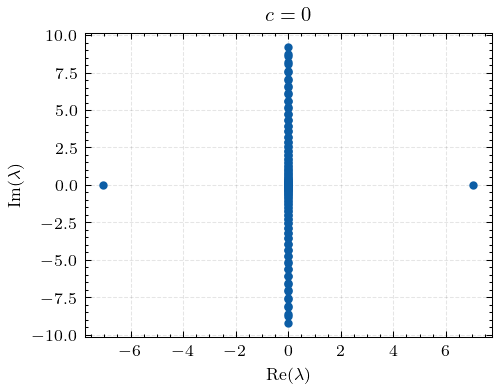

In [6]:
plt.plot(np.real(evals), np.imag(evals), ms=3, ls="")
plt.title(r"$c=0$")
plt.xlabel(r"Re$(\lambda)$")
plt.ylabel(r"Im$(\lambda)$")
plt.savefig("eigenvalues_c_0.pdf", dpi=300, bbox_inches = "tight")
plt.show()

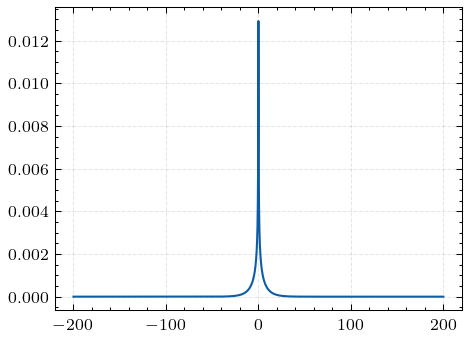

In [11]:
plt.plot(x_uns_black, np.real(p), marker="none")  # eps * v

In [12]:
Nt = 10_000 #10_000
tf = 1 #5 #1 #15

In [13]:
def init_cond_pert(eta, eps=1e-2):
    output = w_uns_black + eps * eta #w_dark_uns(x)
    return output

eta = p + 1j * q

init_cond = init_cond_pert(eta)

In [14]:
k = -50
pars = {"k":k}

# Control
w_uns = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_uns.set_init_array(w_uns_black)
w_uns.solve(b_tol=1e-4)

Iteration  1  of  10000 . Newton Error:  7.993853833433618e-13 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  8.058202162698575e-13 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  8.092379595752731e-13 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  8.047790488574194e-13 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  8.112967562281358e-13 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  8.059135852846935e-13 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  8.002426595950864e-13 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  8.094805067853561e-13 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  8.048285969952409e-13 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  8.044710691999109e-13 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  8.032878066386304e-13 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  7.998170936333848e-13

In [15]:
# perturbed
w_uns_pert = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_uns_pert.set_init_array(init_cond)
w_uns_pert.solve(b_tol=1e-4)

Iteration  1  of  10000 . Newton Error:  2.1986636034251238e-12 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  2.207271601489202e-12 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  2.204619902472381e-12 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  2.1981076900526354e-12 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  2.2034766803824884e-12 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  2.2072872363665715e-12 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  2.205651183278893e-12 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  2.206812171625419e-12 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  2.215192395524204e-12 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  2.213801088568987e-12 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  2.211587703962669e-12 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  2.199013030481768

In [16]:
def theo_dark_uns(x, t):
    output = w_uns_black #(x - c_zero*t)
    return output

# Unstables
w_uns.w_theo = theo_dark_uns
L2_error_uns = w_uns.get_error()

w_uns_pert.w_theo = theo_dark_uns
L2_error_uns_pert = w_uns_pert.get_error()


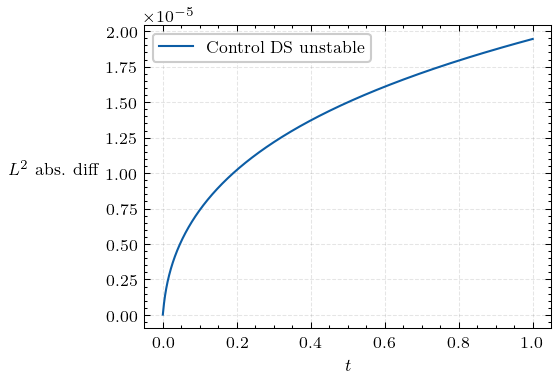

In [17]:
#cond_uns = norm(w_uns_pert.w) != 0
t = w_uns.t
Ti = 0
Tf = 4
cond_t = np.logical_and(Ti<t, t<Tf)

plt.plot(w_uns.t[cond_t], L2_error_uns[cond_t], "-", label="Control DS unstable", marker="none")

plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$ abs. diff ", rotation='horizontal', ha='right')
#plt.xscale("log")
#plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.legend()
plt.show()

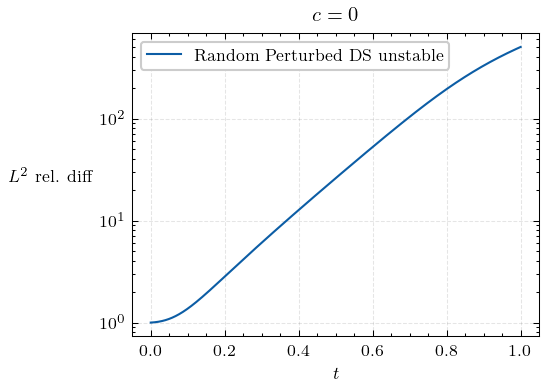

In [18]:
ms = .5

t = w_uns_pert.t
Ti = 0
Tf = 5
cond_t = np.logical_and(Ti<t, t<Tf)

h = w_uns_pert.h
norm_eta = np.sqrt(h) * np_norm(1e-2 * eta, 2)

plt.plot(t[cond_t], L2_error_uns_pert[cond_t]/norm_eta, "-", label="Random Perturbed DS unstable", marker="none")

plt.title(r"$c = 0$")
plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$ rel. diff", rotation='horizontal', ha='right')
#plt.xscale("log")
plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.legend()
plt.show()

In [ ]:
ms = .5

t = w_uns_pert.t

plt.plot(t, e - e[0], marker="none")

plt.title(r"$c = 0$")
plt.xlabel(r"$t$")
plt.ylabel(r"$E(t)$", rotation='horizontal', ha='right')
#plt.xscale("log")
#plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.show()

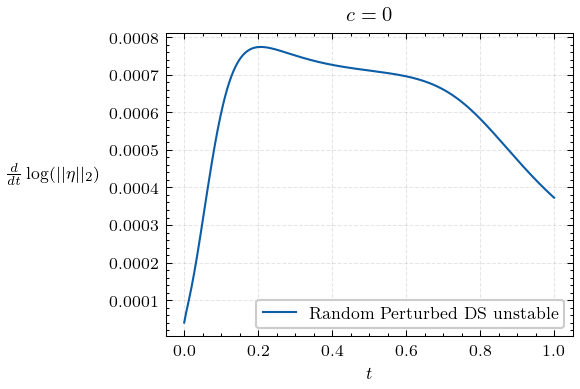

In [20]:
ms = .5

t = w_uns_pert.t
Ti = 0
Tf = 5
cond_t = np.logical_and(Ti<t, t<Tf)

h = w_uns_pert.h
norm_eta = np.sqrt(h) * np_norm(1e-2 * eta, 2)

plt.plot(t[cond_t], np.gradient(np.log(L2_error_uns_pert[cond_t]/norm_eta)), "-", label="Random Perturbed DS unstable", marker="none")

plt.title(r"$c = 0$")
plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{d}{dt}\log(||\eta||_{2})$", rotation='horizontal', ha='right')
#plt.xscale("log")
#plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.legend()
plt.show()

In [160]:
from scipy.optimize import curve_fit

Ti = 0.1
Tf = 0.8

t = w_uns_pert.t
dt = w_uns_pert.dt

cond_t = np.logical_and(Ti<t, t<Tf)

# Exponential

def line_func(t, C, l):
    return l*t + C#C * np.exp(l*t)

pars_uns, other = curve_fit(line_func,  t[cond_t],  np.log(L2_error_uns_pert[cond_t]))
C_uns, l_uns = pars_uns


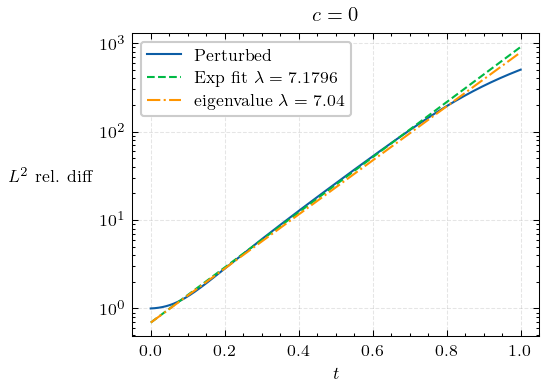

In [170]:
plt.plot(t, L2_error_uns_pert/norm_eta, "-", label="Perturbed", marker="none")

plt.plot(t, np.exp(line_func(t, C_uns, l_uns))/norm_eta, marker="none",
         label=r"Exp fit $\lambda=$ {}".format(round(l_uns, 4)))

plt.plot(t, np.exp(line_func(t, C_uns, np.real(lam)))/norm_eta, marker="none",
         label=r"eigenvalue $\lambda=$ {}".format(round(np.real(lam), 4)))

plt.title(r"$c = 0$")
plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$ rel. diff", rotation='horizontal', ha='right')
#plt.xscale("log")
plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.legend()

plt.savefig("simulation_c_0.pdf", dpi=300, bbox_inches = "tight")
plt.show()

(-20.0, 20.0)

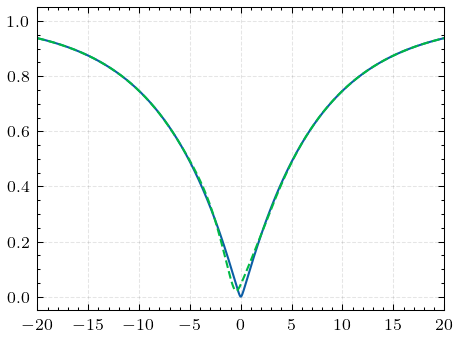

In [163]:
j = 10000-1
#plt.plot(w_uns_pert.x, norm(w_uns_pert.w[0]), marker="none")
plt.plot(w_uns.x, norm(w_uns.w[j]), marker="none")
plt.plot(w_uns_pert.x, norm(w_uns_pert.w[j]), marker="none")
plt.xlim(-20, 20)

In [30]:
def inner(u, v):
    return np.sum(np.conjugate(u) * v)

In [31]:
inner_w_v = []

for j in range(Nt):
    inner_ = inner(w_uns_pert.w[j], 1e-2*eta)
    inner_w_v += [inner_]

inner_w_v = np.array(inner_w_v)

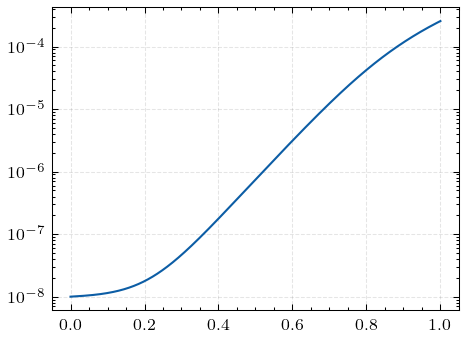

In [32]:
plt.plot(w_uns_pert.t, norm(inner_w_v), marker="none")
plt.yscale("log")
plt.show()

In [53]:
from scipy.optimize import curve_fit

Ti = 0
Tf = 0.04

t = w_uns_pert.t
dt = w_uns_pert.dt

cond_t = np.logical_and(Ti<t, t<Tf)

# Exponential

def line_func(t, C, l):
    return l*t + C#C * np.exp(l*t)

pars_uns, other = curve_fit(line_func,  t[cond_t],  np.log(np.abs(inner_w_v[cond_t])))
C_uns, l_uns = pars_uns


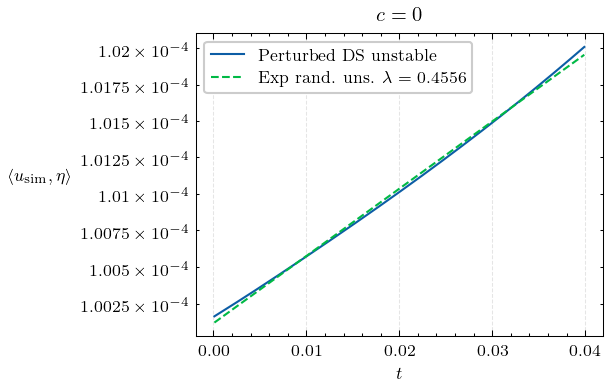

In [54]:
plt.plot(t[cond_t], np.abs(inner_w_v)[cond_t], "-", label="Perturbed DS unstable", marker="none")

plt.plot(t[cond_t], np.exp(line_func(t[cond_t], C_uns, l_uns)), marker="none",
         label=r"Exp rand. uns. $\lambda=$ {}".format(round(l_uns, 4)))

plt.title(r"$c = 0$")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle u_{\text{sim}}, \eta \rangle$", rotation='horizontal', ha='right')
#plt.xscale("log")
plt.yscale("log")
#plt.xlim(-0.1, 0.5)
plt.legend()
plt.show()